# E130: does teacher training's placement protect every copy it makes?

**The answer.** No, the protection depends on which fine-tune is copied. The copy of the full Adam fine-tune stopped after 20 steps reads 2.84 as placed and 2.17 with its own change moved into Δ, so its placement adds excess. The copy of a rank-8 LoRA trained for 2,400 steps reads 1.53 placed and 3.17 in Δ, a fourfold cut like before. Across the four lowercase copies read so far, the placed excess runs from a quarter to one and a half times the excess in Δ. Why is not known.

Report: `reports/analyses/2026-11-07_analysis_e130-copy-protection.md`. Job 55000, MATS `debug` L40, $0, every control reproduced exactly. Provisional: no independent check.


## What we were trying to test

Each matrix of the decomposition is $W = UV^\top + \Delta$, with Γ and Δ frozen. *Teacher training* copies a fine-tuned model into the decomposition by training only the alive subcomponents' vectors $U, V$ on the KL divergence from the fine-tuned model. *The check* is VPD's mask adversary on Pile rows 0-255, one 20-step adversary per block of 128 rows. A state's **ratio** is its adversarial KL over W₀'s: 1 means as hard to break as the released decomposition, and E39's fail line is 1.61. *Do-nothing* leaves the fine-tune's own change in Δ.

A copy's weight change is $S_c = U'V'^\top - UV^\top$. We read it in two places at the same weights. **As placed**, it rides the alive subcomponents, where teacher training put it. **In Δ**, the subcomponents stay at the released $U, V$ and $S_c$ sits in Δ. The multiplier $m = (\text{placed} - 1)/(\text{in Δ} - 1)$ compares the two excesses: under 1 the placement protects, over 1 it exposes.

E127 read two lowercase copies this way and found $m$ of 0.36 and 0.24: teacher training's placement divided the excess by three to four. Here two more copies by the same recipe are read:

- **the step-20 Adam copy**, of the full Adam fine-tune stopped at step 20, with the LoRA's damage to plain text;
- **the step-2,400 LoRA copy**, of a rank-8 LoRA trained on to step 2,400, with the full Adam fine-tune's damage.

If the division belongs to the recipe, both should read $m$ at 0.5 or under.

## What we expected, and why

Fable leaned the other way, at 0.55: the step-20 Adam copy already looked unprotected, its placed excess 76% of its do-nothing's. If its change in Δ read like earlier copies', at most 0.81 of do-nothing's excess, it would read 2.7 to 2.9 there and $m$ near 1. The LoRA copy was expected to stay protected, $m$ 0.25 to 0.4.


## What we observed

### Does teacher training's placement shrink each copy's excess?


copy                              placed  in Delta      m
full Adam, step 300                1.913     3.526   0.36
rank-8 LoRA, step 300              1.326     2.336   0.24
full Adam, step 20 (new)           2.842     2.165   1.58
rank-8 LoRA, step 2,400 (new)      1.534     3.167   0.25


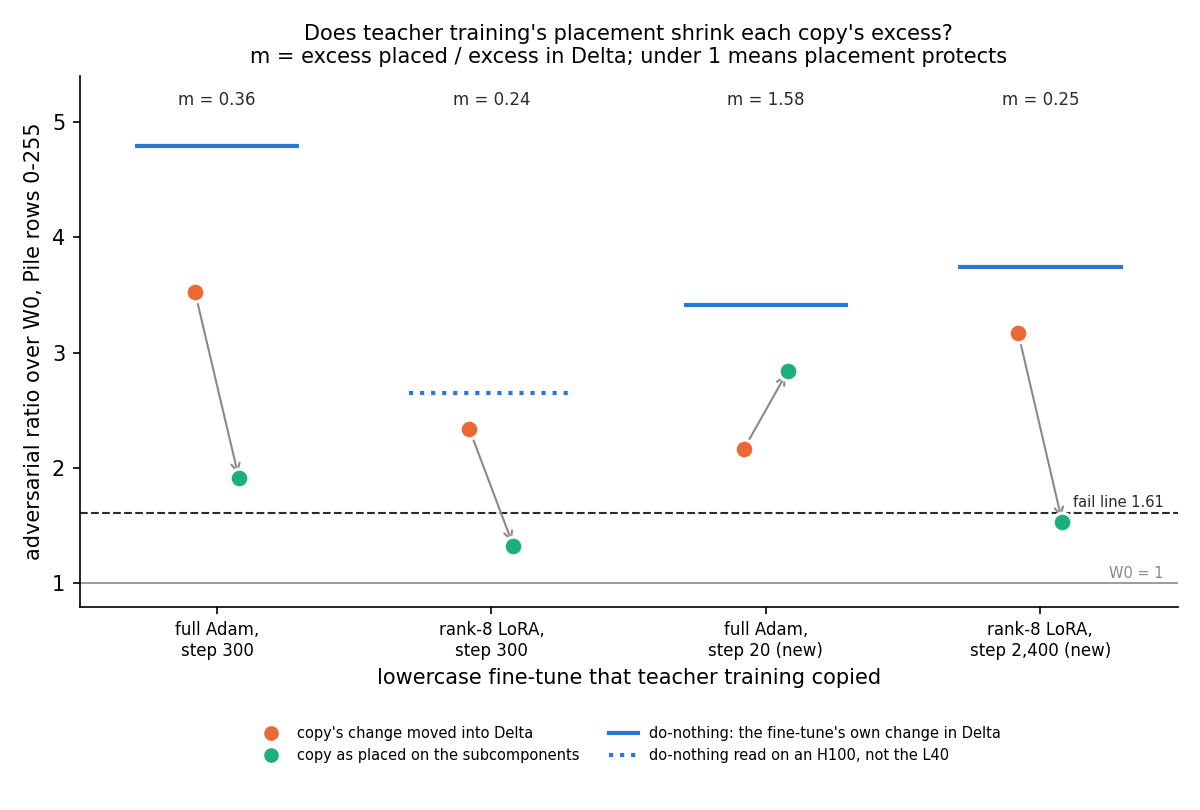

In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
out = json.loads((ROOT / "experiments/copy_protection/results/copy_protection.json").read_text())
a2 = json.loads((ROOT / "experiments/ls_start_faith/results/ls_start_faith_amend2.json").read_text())["score"]["ratio"]
r = out["score"]["ratio"]
rows = [("full Adam, step 300", a2["std_copy"], a2["std_copy|delta"]),
        ("rank-8 LoRA, step 300", a2["lora_copy"], a2["lora_copy|delta"]),
        ("full Adam, step 20 (new)", r["c1"], r["c1|delta"]),
        ("rank-8 LoRA, step 2,400 (new)", r["c2"], r["c2|delta"])]
print(f"{'copy':32s}{'placed':>8s}{'in Delta':>10s}{'m':>7s}")
for name, placed, delta in rows:
    print(f"{name:32s}{placed:8.3f}{delta:10.3f}{(placed - 1) / (delta - 1):7.2f}")
display(Image(filename=str(ROOT / "experiments/copy_protection/figures/placement.png")))


**Reading it.** Not for every copy: on the step-20 Adam copy the placement makes the excess larger. Each orange point is a copy's change in Δ, each green point the same change as placed. On three copies the arrow points down, to a quarter or a third of the in-Δ excess. On the step-20 Adam copy it points up: 2.17 in Δ becomes 2.84 placed, so $m$ is 1.58. All four in-Δ reads sit under their own do-nothing, the blue bar, and the step-20 copy's furthest under it. So that copy carries a change that would read fairly well in Δ, and teacher training placed it where the adversary finds more. One seed and one row set per copy; the reversal comes from one of the two 128-row blocks, where the placed copy reads 4.35 and its change in Δ 2.91.

## What we learned

Teacher training's placement is not a constant of the recipe. Across the four lowercase copies trained from W₀'s start, $m$ runs from 0.24 to 1.58. As description only, one seed each: the two copies of rank-8 LoRA fine-tunes read 0.24 and 0.25, the two copies of full Adam fine-tunes 0.36 and 1.58. Damage to plain text does not order them. Teacher training's loss has no mask or adversary term, so nothing asks for protection, and here it did not always come. For `GOALS.md`, a carrier for broad updates needs a placement that protects by design.

## How compelling is the evidence

One adversary seed, one row set, one card. Every control reproduced to the last digit. The step-20 copy's verdict sits 5.4 floors from its edge, but rests on one block of 128 rows. The LoRA copy's placed excess is only 2.6 floors, so its $m$ is coarse, 0.14 to 0.38 within a floor. The two new copies sit at the same input-weighted cosine to their fine-tunes, 0.58 and 0.59, yet are placed with opposite effect.

## Surprises

Placement made one copy worse: we expected $m$ near 1 for the step-20 Adam copy and read 1.58. Its in-Δ ratio, 2.17, fell under the lean band of 2.7 to 2.9. The LoRA copy's values sat just outside their bands, a narrow miss.

## What next

- The step-20 copy's change in Δ on Pile rows 256-511, where placed it reads 1.44: does the reversal hold on a second row set? About 3 min, $0.
- Where each of the four copies' changes sits against Γ's causal importances: the two new copies give a contrast to explain.
- Teacher training with a masked or adversarial term, the synthesis' run for the broad failure.

## Scorecard

| id | rule | read | verdict |
|---|---|---|---|
| C1, C2 | W₀ and both placed copies within 1e-3 of stored | exact | held |
| R2 c1 | m ≤ 0.5 recipe-like, ≥ 0.8 no protection | 1.58 | no protection, as leaned |
| R2 c2 | same | 0.25 | recipe-like, as leaned |
| R3 | any no protection → function-dependent | | function-dependent, as leaned |
| lean c1 in Δ | 2.7-2.9 | 2.17 | missed low |

**Not run:** adversary seeds 1-2 and rows 256-511 for the in-Δ reads; the causal-importance placement read; cosines of E127's two copies; the LoRA's do-nothing on the L40; more copies or tasks; an independent check.
